# Занятие 3, пара 2. Шум, нелинейные фильтры и масштаб


Автор ноутбука - Дуркин Анатолий Альбертович

Старший преподаватель кафедры прикладной математики и компьютерных наук СГУ им. Питирима Сорокина

Замечания, предложения, идеи, вопросы, связь с автором:
- anatoliy.durkin@mail.ru
- Telegram - @AnatoDu

Больше информации и материалов на канале автора: https://t.me/code_matan_ai


## Выберите маршрут до запуска

- Если OpenCV установлен: основной разбор ниже, с библиотечной реализацией.
- Если доступны NumPy и Matplotlib: перейдите сразу к разделу [«Самостоятельная работа без OpenCV»](#numpy-route) в конце тетради. Это полноценный вычислительный путь с объяснениями и упражнениями, предыдущие ячейки запускать не нужно.

Выберите **один** маршрут на эту пару. Не запускайте всю тетрадь командой Run All: она содержит два альтернативных пути. Готовые картинки помогают сравнить результат, но не заменяют собственный опыт. Сохраните копию с ответами; GitHub необязателен.


Размывать мы научились. Но зачем это вообще делать? Попробуем убрать помехи и заодно убедимся, что «размыть посильнее» — не универсальный рецепт счастья.

Сегодня оригинал известен: мы сами создадим испорченную копию. Поэтому сможем проверить и глазами, и числами. На настоящем шумном снимке чистого оригинала обычно нет — это важное ограничение нашего эксперимента.


### Подключим учебные файлы

Следующая ячейка — служебная настройка комплекта. Она находит папку `course_support` у текущей папки или выше и подключает данные и проверки. Её не нужно писать по памяти или менять для задания. `DATA_DIR` — путь к учебным данным, `WORKSPACE_DIR` — корень вашей рабочей папки. `check(номер, ответы)` сравнивает ответ с условиями упражнения, но не выставляет оценку.

Работайте в своей копии и запускайте ячейки сверху вниз. Переменные из другой тетради не нужны. Если поддержку не удалось найти, откройте тетрадь внутри полного комплекта, а не переносите один файл отдельно. Git и интернет для основной работы не нужны.


In [ ]:
import sys
from pathlib import Path

# Одинаковый запуск в репозитории курса и в личном проекте.
for WORKSPACE_DIR in (Path.cwd(), *Path.cwd().parents):
    if (WORKSPACE_DIR / 'course_support' / '__init__.py').is_file():
        break
else:
    raise FileNotFoundError('Откройте тетрадь внутри папки с course_support; нужен весь комплект проекта')

# При переключении курса в том же kernel не оставляем чужую поддержку в памяти.
loaded = sys.modules.get('course_support')
expected = WORKSPACE_DIR / 'course_support' / '__init__.py'
if loaded is not None and Path(loaded.__file__).resolve() != expected.resolve():
    for name in list(sys.modules):
        if name == 'course_support' or name.startswith('course_support.'):
            del sys.modules[name]
sys.path.insert(0, str(WORKSPACE_DIR))
from course_support import SUPPORT_DIR, DATA_DIR
COURSE_DIR = SUPPORT_DIR
# Только упражнения о личном README: в репозитории курса это ещё чистый шаблон.
PROJECT_DIR = WORKSPACE_DIR / 'project_template' if (WORKSPACE_DIR / 'project_template').is_dir() else WORKSPACE_DIR
from course_support.checks import check, summary

PROJECT_DIR


### Что подключаем

`numpy` хранит изображение как таблицу чисел; короткое имя — `np`. `cv2` — OpenCV, библиотека обработки изображений. `imread`, `imwrite` и `show` — три помощника курса: прочитать файл, сохранить массив как картинку и показать картинку. Они также помогают с русскими буквами в путях. Сейчас достаточно знать их входы и результат; сами фильтры будем разбирать без этих помощников на маленьких массивах.


In [ ]:
import numpy as np
import cv2
from course_support.cvtools import imread, imwrite, show


`/` между путём и строкой здесь соединяет папку и имя, а не делит числа. Результаты будем сохранять отдельно от исходных данных. `mkdir` создаёт папку; `parents=True` разрешает создать промежуточные папки, `exist_ok=True` не ругается, если папка уже есть.


In [ ]:
OUTPUT_DIR = WORKSPACE_DIR / 'reports' / 'filters'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


Прочитаем фотографию из комплекта. Второй аргумент `cv2.IMREAD_GRAYSCALE` просит одну яркость на пиксель вместо трёх цветовых каналов. `show` принимает массив, а `titles` — список подписей: одна подпись на изображение.


In [ ]:
clean = imread(DATA_DIR / 'hopper.jpg', cv2.IMREAD_GRAYSCALE)
show(clean, titles=['Учебная фотография'])


`shape` сообщает размеры массива: сначала высоту (число строк), потом ширину (число столбцов). `dtype` — тип одного числа. `uint8` хранит целые значения от 0 до 255: 0 — чёрный, 255 — белый. `min()` и `max()` находят крайние значения. Скобки означают вызов действия; у свойств `shape` и `dtype` их нет.


In [ ]:
print('Размер:', clean.shape)
print('Тип:', clean.dtype)
print('Яркости:', clean.min(), clean.max())


Для сравнения у всех возьмём одинаковый небольшой размер. `cv2.resize` получает изображение и **(ширину, высоту)** — порядок обратный `shape`. `interpolation` определяет, как вычислять новые пиксели; `INTER_AREA` усредняет вклад площадей при уменьшении. Сейчас это подготовка фотографии; отдельно изменение размера разберём в 03.2.


In [ ]:
clean = cv2.resize(clean, (256, 300), interpolation=cv2.INTER_AREA)
print(clean.shape)


## Шум из нескольких чисел

Создадим **генератор случайных чисел**. `default_rng(42)` — его настройка с начальным числом, которое называют seed. Одинаковый seed и одинаковая последовательность вызовов дают воспроизводимый опыт. Это не «лучший» seed, просто удобная договорённость.

`normal(0, 20, size=5)` просит пять случайных отклонений: распределение вокруг нуля, типичный масштаб 20. Положительное отклонение осветлит пиксель, отрицательное затемнит. 20 не предел: иногда модуль будет больше.


In [ ]:
rng = np.random.default_rng(42)
noise_demo = rng.normal(0, 20, size=5)
print(noise_demo)


Пусть наши пять пикселей имели яркость 100. Сначала сложим исходник и отклонения. `astype(float)` разрешает дроби и отрицательные промежуточные значения. Затем знакомые `clip` и `astype(np.uint8)` подготовят результат для картинки.

`np.array` превращает список чисел в массив; `dtype` выбирает тип его элементов.


In [ ]:
row = np.array([100, 100, 100, 100, 100], dtype=np.uint8)
row_float = row.astype(float)
changed_row = row_float + noise_demo
print(changed_row)
limited_row = np.clip(changed_row, 0, 255)
print(limited_row.astype(np.uint8))


Вместо пяти отклонений попросим целую таблицу размера `clean.shape`. Это по одному отклонению для каждого пикселя. Затем соберём ровно те же действия в функцию. Значения после `=` в объявлении — параметры по умолчанию; их можно изменить при вызове.


In [ ]:
def add_gaussian(image, sigma=20, seed=42):
    rng = np.random.default_rng(seed)
    noise = rng.normal(0, sigma, size=image.shape)
    work = image.astype(float)
    changed = work + noise
    limited = np.clip(changed, 0, 255)
    return limited.astype(np.uint8)

gaussian_noisy = add_gaussian(clean)
show(clean, gaussian_noisy, titles=['Оригинал', 'Гауссов шум'])


Прежде чем идти дальше: поменяйте sigma на 5, затем на 40 в отдельной ячейке. Назовите один участок, где шум заметнее. Это та же фотография и тот же вид помехи, изменилась сила. На обсуждение и пробу — 3 минуты.


## Другой шум: «соль и перец»

Теперь часть пикселей заменим целиком на чёрные или белые. Выбор места начнём с простой таблицы чисел от 0 до 1. Условие `< 0.04` строит **маску**: на месте подходящего числа будет `True`, на остальных `False`. Запись `массив[маска] = 0` меняет только отмеченные элементы.


In [ ]:
probability_demo = np.array([0.02, 0.5, 0.98, 0.3, 0.01])
black_mask = probability_demo < 0.04
print(black_mask)
row_copy = row.copy()
row_copy[black_mask] = 0
print(row_copy)


`copy()` сохранил исходный `row`. Белыми сделаем элементы, где число больше 0.96. Два порога оставляют около 4% чёрных и 4% белых позиций при случайном выборе. Для пяти чисел доля, конечно, не будет ровно 8%.


In [ ]:
white_mask = probability_demo > 0.96
row_copy[white_mask] = 255
print(row_copy)
print('Исходник:', row)


`rng.random(форма)` генерирует числа от 0 до 1 для всего изображения. Вместо жёстких 0.04 и 0.96 выразим пороги через общую долю `amount`: половину отдаём чёрным, половину белым.

`if not 0 <= amount <= 1` проверяет допустимость доли. Если она неверна, `raise ValueError` сообщает причину, вместо того чтобы молча создать странную картинку. Внутри функции больше нет новых действий.

Метод массива `.copy()` создаёт независимую копию: запись шума в неё не изменит исходное изображение.


In [ ]:
def add_impulse(image, amount=0.08, seed=42):
    if not 0 <= amount <= 1:
        raise ValueError('Доля шума должна быть от 0 до 1')
    rng = np.random.default_rng(seed)
    probabilities = rng.random(image.shape)
    noisy = image.copy()
    black = probabilities < amount / 2
    white = probabilities > 1 - amount / 2
    noisy[black] = 0
    noisy[white] = 255
    return noisy

impulse_noisy = add_impulse(clean)
show(clean, impulse_noisy, titles=['Оригинал', 'Соль и перец'])


### ✏️ Ваш ход — добавляем помеху сами

Создайте `my_noisy` функцией `add_impulse`: amount=0.08, seed=42. Сравните с исходником. После проверки в новой ячейке попробуйте amount=0.2, сохранив прежнее `my_noisy`. Что изменилось: вид шума или его количество?


In [ ]:
# ✏️ ваш код здесь


In [ ]:
check('03.2.1', my_noisy, clean)


**Мой вывод:** замените эту строку своим объяснением результата. Назовите конкретное число, поле или участок изображения, на который опираетесь.


## Почему среднее не всегда спасает

Снова девять соседей. Восемь имеют яркость 10, один — 255. Среднее окажется около 37: яркая точка потянет за собой всё окно. `.mean()` — короткая запись суммы, делённой на количество.


In [ ]:
values = np.array([10, 10, 10, 10, 255, 10, 10, 10, 10])
print(values.mean())


А если упорядочить значения и взять среднее **по положению**, не по арифметике? `np.sort` возвращает отсортированную копию. При девяти элементах середина имеет индекс 4. Это медиана. `np.median` вычисляет её сразу; при чётном количестве она берёт среднее двух центральных чисел.


In [ ]:
ordered = np.sort(values)
print(ordered)
print(ordered[4])
print(np.median(values))


`cv2.blur(изображение, (3,3))` — готовое усреднение, эквивалент знакомому ядру 1/9. `cv2.medianBlur(изображение, 3)` — медиана в окне 3×3; здесь размер передаётся одним нечётным числом. Сначала сравним на маленьком участке: используем `reshape(3,3)`, чтобы разложить девять значений в три строки, не меняя их порядок.


In [ ]:
tiny = values.astype(np.uint8)
tiny = tiny.reshape(3, 3)
print(tiny)
tiny_median = cv2.medianBlur(tiny, 3)
print(tiny_median)


Попробуем обычное среднее на шумной фотографии. Посмотрите, исчезли ли белые точки или превратились в светлые пятна. Исходный шум заново не генерируем: сравнивать надо на одной и той же испорченной картинке.


In [ ]:
averaged = cv2.blur(my_noisy, (3, 3))
show(my_noisy, averaged, titles=['Шум', 'Среднее 3×3'])


### ✏️ Ваш ход — пробуем медиану

Получите `median_result` с помощью `cv2.medianBlur(my_noisy, 3)`. Покажите рядом с `clean` и `my_noisy`. Потом отдельно попробуйте окно 7. Назовите одну деталь, которую большой фильтр испортил вместе с шумом.


In [ ]:
# ✏️ ваш код здесь


In [ ]:
check('03.2.2', median_result, my_noisy)


**Мой вывод:** замените эту строку своим объяснением результата. Назовите конкретное число, поле или участок изображения, на который опираетесь.


## Давайте проверим числами

На двух пикселях считать удобнее. Пусть эталон `[10,20]`, результат `[12,17]`. Вычитаем **дробные** значения: ошибки −2 и 3. Квадраты 4 и 9 не дают плюсу и минусу взаимно уничтожиться. `**2` возводит каждую ошибку в квадрат.


In [ ]:
reference_demo = np.array([10, 20], dtype=float)
result_demo = np.array([12, 17], dtype=float)
error_demo = reference_demo - result_demo
squared_error_demo = error_demo ** 2
print(error_demo)
print(squared_error_demo)


Среднее квадратов называется MSE. Здесь `(4+9)/2 = 6.5`. Чем меньше MSE, тем ближе значения к эталону. Это не обязательно означает, что человеку больше понравится картинка.


In [ ]:
mse_demo = squared_error_demo.mean()
print(mse_demo)


Часто ту же ошибку выражают через PSNR. Для пикселей 0…255 формула такая:

$$PSNR = 10\log_{10}(255^2/MSE).$$

`np.log10` — десятичный логарифм: например, log10(100)=2, потому что 10²=100. Сейчас не нужно выводить формулу: разберём порядок вычислений. Делим квадрат максимальной яркости на MSE, берём логарифм, умножаем на 10. При одинаковом эталоне **больше PSNR — меньше MSE**.


In [ ]:
ratio_demo = 255 ** 2 / mse_demo
log_demo = np.log10(ratio_demo)
score_demo = 10 * log_demo
print(score_demo)


Соберём действия в функцию. Сначала проверим размер. При полном совпадении MSE=0; деление на ноль заменяем явным `float('inf')` — бесконечностью. В остальных случаях выполняем уже разобранную формулу.


In [ ]:
def psnr(reference, result):
    if reference.shape != result.shape:
        raise ValueError('Нужны изображения одинакового размера')
    reference_float = reference.astype(np.float64)
    result_float = result.astype(np.float64)
    difference = reference_float - result_float
    squared = difference ** 2
    mse = squared.mean()
    if mse == 0:
        return float('inf')
    ratio = 255 ** 2 / mse
    return float(10 * np.log10(ratio))

print('Исходник с самим собой:', psnr(clean, clean))


Теперь сравним три версии. Они построены из одной `my_noisy`, поэтому опыт честный. Запишите прогноз перед запуском. Единица PSNR — децибел (dB). Число само по себе не является оценкой за лабораторную.


In [ ]:
score_noisy = psnr(clean, my_noisy)
score_mean = psnr(clean, averaged)
score_median = psnr(clean, median_result)
print('Без фильтра:', score_noisy)
print('Среднее:', score_mean)
print('Медиана:', score_median)


**Самостоятельный опыт — 7–8 минут.** Возьмите уже созданную `gaussian_noisy`. Получите среднее 3×3 и медиану 3×3, посчитайте PSNR для исходного шума и обоих результатов. Не создавайте новый шум для каждого фильтра. Сохранился ли победитель? Проверьте глазами тот же участок, что рассматривали при импульсном шуме. Впишите параметр, два числа и одно наблюдение.

Эталон нам известен только потому, что опыт искусственный. PSNR не измеряет понимание сцены и не доказывает, что метод лучший для любых фотографий.


In [ ]:
# Здесь ваш опыт с gaussian_noisy; можно повторить три короткие ячейки выше.


### Сохраним сравнение

Здесь пригодится стандартный модуль `csv`. Список внутри списка задаёт строки будущего файла. `with ... as file` открывает файл на время блока и затем закрывает его. Режим `'w'` записывает файл заново, `newline=''` позволяет модулю правильно оформлять переводы строк. `writerows` записывает подготовленные строки. Это сохранение результата, новых методов обработки тут нет.

Здесь `.open` — метод пути к файлу. `csv.writer(file)` создаёт объект записи CSV, которому затем передаём строки через `.writerows`.


In [ ]:
import csv
rows = [['method', 'psnr_db'],
        ['Без фильтра', score_noisy],
        ['Среднее 3', score_mean],
        ['Медиана 3', score_median]]
with (OUTPUT_DIR / 'comparison.csv').open('w', newline='', encoding='utf-8') as file:
    writer = csv.writer(file)
    writer.writerows(rows)
imwrite(OUTPUT_DIR / 'denoised.png', median_result)


## «Увеличить!»

Уменьшение и увеличение — разные задачи. Напомним: `shape` возвращает высоту, ширину; `resize` принимает ширину, высоту. Оператор `//` делит с округлением вниз: нужен целый размер. Начнём с маленького массива 4×4, чтобы увидеть числа.


In [ ]:
resize_demo = np.array([[0, 0, 100, 100],
                        [0, 0, 100, 100],
                        [200, 200, 255, 255],
                        [200, 200, 255, 255]], dtype=np.uint8)
demo_small = cv2.resize(resize_demo, (2, 2), interpolation=cv2.INTER_AREA)
print(demo_small)


`INTER_AREA` учитывает площади исходных пикселей при уменьшении. Вернём 4×4 двумя способами. `INTER_NEAREST` копирует ближайший пиксель, `INTER_LINEAR` смешивает ближайших соседей с весами по расстоянию. Во втором случае переход плавнее; отсутствующие детали от этого не становятся известными.


In [ ]:
demo_nearest = cv2.resize(demo_small, (4, 4), interpolation=cv2.INTER_NEAREST)
demo_linear = cv2.resize(demo_small, (4, 4), interpolation=cv2.INTER_LINEAR)
print('Ближайший сосед:\n', demo_nearest)
print('Линейная интерполяция:\n', demo_linear)


### ✏️ Ваш ход — тот же размер, другие пиксели

Уменьшите `clean` по ширине и высоте в 4 раза через INTER_AREA: результат `small_image`. Затем верните исходный размер через INTER_NEAREST (`up_nearest`) и INTER_LINEAR (`up_linear`). Покажите рядом с оригиналом, вычислите PSNR, укажите одну утраченную деталь. Все необходимые операции уже есть в примере выше.


In [ ]:
# ✏️ ваш код здесь


In [ ]:
check('03.2.3', small_image, up_nearest, up_linear, clean)


**Мой вывод:** замените эту строку своим объяснением результата. Назовите конкретное число, поле или участок изображения, на который опираетесь.


## Запас для тех, кто закончил: один опыт, а не четыре запуска подряд

На 10–15 минут выберите один вопрос. Что меняется при другом seed? Как соотносятся окна медианы 3 и 7 при amount=0.2? Где фильтр полезен: на ровном фоне или на мелком тексте? Для участка используйте уже знакомый срез, например `clean[80:130, 50:100]`; те же границы возьмите у обработанной картинки. Сначала прогноз, потом опыт, потом один вывод с числами.

Ещё один инструмент — **билатеральный фильтр**. Он учитывает и расстояние до соседа, и сходство яркости: старается меньше смешивать разные стороны границы. `d=5` — диаметр окна, `sigmaColor=40` — допустимый масштаб различий яркости, `sigmaSpace=3` — расстояния. Ни один параметр не гарантирует хорошего результата. Если интересно, сравните один вызов ниже со средним на том же гауссовом шуме.

В OpenCV этот метод вызывается как `cv2.bilateralFilter`.


In [ ]:
bilateral = cv2.bilateralFilter(gaussian_noisy, d=5, sigmaColor=40, sigmaSpace=3)
show(gaussian_noisy, bilateral, titles=['Гауссов шум', 'Билатеральный'])
print(psnr(clean, bilateral))


## Перед закрытием

Сохраните тетрадь, `comparison.csv` и `denoised.png` из `reports/filters`, проверьте отдельную копию. Впишите итог: какой шум, какой фильтр, параметр, PSNR до/после и что видно глазами. Почему нужно сравнивать на одном шуме? Что мы потеряли при уменьшении?

Это тренировка для ЛР 2, полное задание — после краёв и контуров. Новых баллов или обязательной публикации на GitHub нет. По желанию: [OpenCV — фильтрация](https://docs.opencv.org/4.x/d4/d13/tutorial_py_filtering.html), [книга Сзелиски](https://szeliski.org/Book/).


In [ ]:
summary('03.2')


<a id="numpy-route"></a>
## Самостоятельная работа без OpenCV: NumPy и Matplotlib

Это отдельный маршрут той же пары. Начните **здесь в новом ядре**: предыдущие ячейки OpenCV не нужны. Выполняйте только этот раздел до конца. «Запустить все ячейки» для всей тетради не используем, потому что выше расположен альтернативный маршрут с OpenCV. Для обеих версий результат — ваш опыт, объяснение и сохранённый файл, а не число зелёных галочек.

Здесь нет проверки `03.x.1–3`: она относится к реализации на OpenCV выше. В этом маршруте сверяйте маленькие расчёты с разобранными примерами и объясняйте наблюдения; требования ЛР2 одинаковые. Готовые иллюстрации ниже — только ориентир для обсуждения, не ваш выполненный эксперимент.


`numpy` хранит изображение как массив чисел, `matplotlib.pyplot` показывает его. Сокращения `np` и `plt` просто удобные имена. Данные создадим прямо в тетради; ни интернет, ни соседние тетради не нужны.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt


### 1. Создадим известный исходник

`np.full((40,60), 30.0)` создаёт 40 строк и 60 столбцов, заполненных яркостью 30. Срез `[10:30,15:45]` выбирает прямоугольник: строки 10…29, столбцы 15…44. Присвоим ему яркость 180. Отдельная тонкая линия покажет, что фильтр может потерять полезную деталь.


In [ ]:
clean = np.full((40, 60), 30.0)
clean[10:30, 15:45] = 180
clean[5, 10:50] = 220
print(clean.shape)


Покажем исходник. `imshow` отображает двумерный массив, `cmap='gray'` — серую шкалу, `vmin=0, vmax=255` — единый диапазон сравнения. `title` — подпись, `show` — показ. Заодно найдите прямоугольник и тонкую линию.


In [ ]:
plt.imshow(clean, cmap='gray', vmin=0, vmax=255)
plt.title('Чистый синтетический исходник')
plt.show()


### 2. Добавим редкие чёрные и белые точки

`np.random.default_rng(42)` создаёт генератор псевдослучайных чисел. Начальное значение 42 — seed; повторная инициализация с тем же seed повторит числа. `rng.random(clean.shape)` создаёт массив от 0 до 1 той же формы. Сравнения `<0.04` и `>0.96` выбирают примерно по 4% пикселей, но точное количество на маленькой картинке может отличаться.

У булева массива `.sum()` считает True: единица за каждый выбранный пиксель.


In [ ]:
rng = np.random.default_rng(42)
random_values = rng.random(clean.shape)
black_points = random_values < 0.04
white_points = random_values > 0.96
print(black_points.sum(), white_points.sum())


Булева маска — массив True/False. Запись `noisy[black_points] = 0` меняет только выбранные позиции. Сначала `.copy()` создаёт отдельную картинку: чистый исходник понадобится для сравнения. Это импульсный шум, который часто называют «соль и перец».


In [ ]:
noisy = clean.copy()
noisy[black_points] = 0
noisy[white_points] = 255
plt.imshow(noisy, cmap='gray', vmin=0, vmax=255)
plt.title('Один и тот же шум для всех фильтров')
plt.show()


### 3. Почему среднее и медиана ведут себя по-разному

`.mean()` — среднее арифметическое массива: сумма, делённая на количество. `np.median` — центральное значение после упорядочивания; для чётного количества — среднее двух центральных. `np.sort` покажет порядок на маленьком **одномерном** примере. Один выброс 255 сильно сдвигает среднее, но не обязан сдвигать медиану.


In [ ]:
values = np.array([20, 20, 21, 19, 255], dtype=float)
ordered = np.sort(values)
print(ordered)
print(values.mean())
print(np.median(values))


### ✏️ Ваш ход — медиана окна с выбросом

Создайте окно 3×3: восемь значений 40 и центральное 255. Рассчитайте `mean_center` и `median_center`. `.mean()` и `np.median` без указания оси берут все элементы окна. Какой результат ближе к исходным 40? Измените 255 на 0: сохраняется ли вывод?


In [ ]:
# ✏️ ваш код здесь


**Мой вывод:** что изменил, что ожидал, что получил и почему. …


### 4. Пройдём по изображению

Функция ниже повторяет устройство фильтра из 03.1: рамка, два цикла, окно, одно число на выходе. `mode='reflect'` отражает края; `zeros_like(..., dtype=float)` создаёт результат. Параметр `method` выбирает среднее или медиану. `raise ValueError` сообщает об ошибочном имени метода. Мы не используем переменные другой тетради: функция полностью определена здесь.

`np.pad(source, 1, ...)` добавляет рамку толщиной один пиксель со всех сторон. `source.shape` даёт высоту и ширину, которые получают два имени слева от знака равенства. Срез `[y:y+3, x:x+3]` выбирает окно 3×3; правые границы не включаются.


In [ ]:
def denoise3(source, method):
    height, width = source.shape
    padded = np.pad(source, 1, mode='reflect')
    result = np.zeros_like(source, dtype=float)
    for y in range(height):
        for x in range(width):
            patch = padded[y:y+3, x:x+3]
            if method == 'mean':
                value = patch.mean()
            elif method == 'median':
                value = np.median(patch)
            else:
                raise ValueError('method: mean или median')
            result[y, x] = value
    return result

mean_image = denoise3(noisy, 'mean')
median_image = denoise3(noisy, 'median')


Посмотрим результаты в одинаковом масштабе яркости. Сравните не только гладкий фон, но и границу прямоугольника, тонкую линию. Медиана может отлично убрать отдельные точки и одновременно удалить линию толщиной один пиксель: для её окна это тоже редкие значения.


In [ ]:
plt.imshow(mean_image, cmap='gray', vmin=0, vmax=255)
plt.title('Среднее 3×3')
plt.show()
plt.imshow(median_image, cmap='gray', vmin=0, vmax=255)
plt.title('Медиана 3×3')
plt.show()


### 5. Добавим число к сравнению картинок

Вычтем чистое изображение из результата — получим ошибку каждого пикселя. Возведём в квадрат, чтобы положительные и отрицательные ошибки не уничтожали друг друга. `.mean()` даст среднюю квадратичную ошибку, MSE. Меньше — ближе к **этому известному исходнику** по этой метрике. Без чистого эталона такой расчёт недоступен.


In [ ]:
errors = noisy - clean
squared_errors = errors ** 2
noisy_mse = squared_errors.mean()
print('MSE испорченной картинки:', noisy_mse)


### ✏️ Ваш ход — сравнить два фильтра на одном шуме

Рассчитайте `mean_mse` и `median_mse` относительно `clean`, каждый в три шага. Сравните с `noisy_mse`. В выводе назовите победителя **в этом опыте**, а затем потерянную деталь, которую одно число скрывает. Не создавайте новый шум для каждого фильтра.


In [ ]:
# ✏️ ваш код здесь


**Мой вывод:** что изменил, что ожидал, что получил и почему. …


**Дополнительный опыт, 5–8 минут.** Создайте новый генератор с seed 7 и повторите шум/оба фильтра/две ошибки. Все методы опять получают один и тот же испорченный кадр. Сравните порядок методов и значения. При желании увеличьте долю шума до примерно 20%: условия `<0.10` и `>0.90`. Меняйте один фактор за раз.

Для другого типа шума результат может быть другим. Например, `rng.normal(0, 10, clean.shape)` создаёт нормально распределённые отклонения с центром 0 и стандартным отклонением 10 для каждого пикселя. Их можно прибавить к `clean`; не называйте это солью и перцем. Если пробуете, явно подпишите тип шума и сохраните одинаковый испорченный исходник для обоих методов.


Сохранённое сравнение фильтров на фотографии в основном маршруте с OpenCV. Здесь другие данные и реализация обработки краёв; не ожидайте численного совпадения со своей маленькой сценой. Сравните общий характер: отдельные точки, размытие границ, мелкие детали.

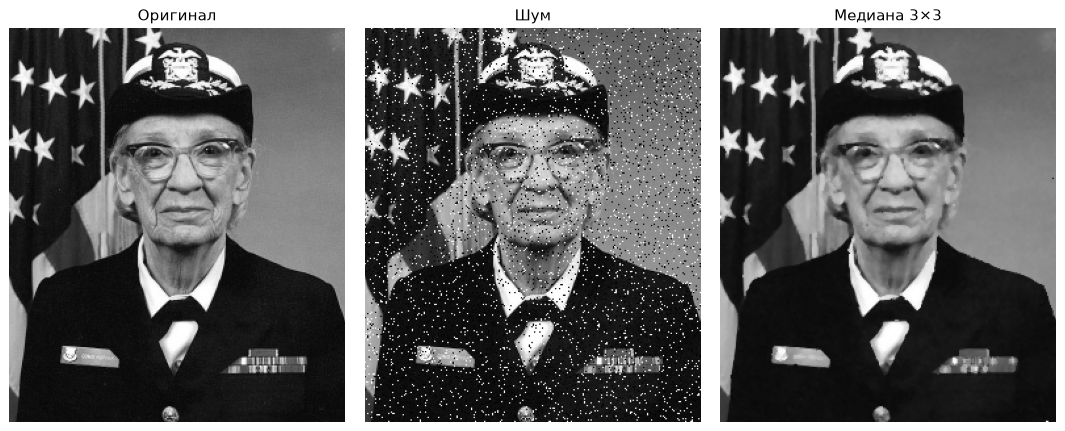


### 6. Увеличить картинку — не значит вернуть детали

Возьмём маленькую таблицу. `np.repeat(small, 2, axis=0)` повторяет каждую строку дважды; `axis=1` — каждый столбец. Получится увеличение в два раза ближайшим соседом для целого коэффициента. Новых промежуточных оттенков нет: исходный пиксель превратился в блок 2×2.


In [ ]:
small = np.array([[0, 100], [180, 255]], dtype=float)
repeated_rows = np.repeat(small, 2, axis=0)
large = np.repeat(repeated_rows, 2, axis=1)
print(large)
plt.imshow(large, cmap='gray', vmin=0, vmax=255)
plt.title('Увеличение повторением пикселей')
plt.show()


При уменьшении информация может потеряться. Срез `source[::2, ::2]` берёт каждую вторую строку и столбец, начиная с нулевых. Это **намеренно наивное прореживание**, без усреднения и сглаживания. На мелком узоре оно даст ложный результат — пример алиасинга. Для качественного уменьшения обычно учитывают несколько исходных пикселей; в OpenCV для такой задачи часто используют INTER_AREA. Сейчас покажем проблему на числах.


### ✏️ Ваш ход — потерять шахматный узор

Создайте массив 4×4 с чередованием 0 и 255, первая строка `[0,255,0,255]`, следующая `[255,0,255,0]`, затем повтор. Получите `tiny = chess[::2,::2]`, увеличьте его обратно через два вызова `np.repeat` в `restored`. Покажите исходник и результат, объясните, почему увеличение не вернуло узор. Резерв: начните с индекса 1 по столбцам — `chess[::2,1::2]`.


In [ ]:
# ✏️ ваш код здесь


**Мой вывод:** что изменил, что ожидал, что получил и почему. …


Сохранённое сравнение способов увеличения из OpenCV-маршрута: ближайший сосед даёт блоки, линейная интерполяция — переходы между соседями. Более гладко не означает, что утерянные детали восстановлены. Найдите один участок, на котором различие хорошо заметно.

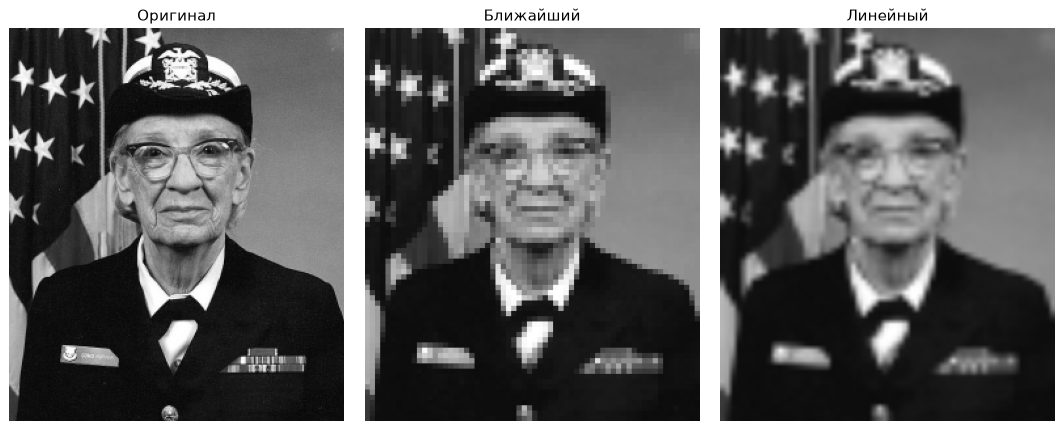


### Итог

Сохраните три упражнения, значения ошибок и пояснения по шуму/деталям/масштабу. Вы создали повторяемый шум, применили два фильтра на одинаковых данных и показали потерю информации. Это самостоятельная практическая работа на NumPy, допустимая для ЛР2. В блоке 04 весь основной маршрут также работает без OpenCV: понадобятся именно массивы, окна и сравнение результатов.
